**Q1**

Original Text:
 Technology makes our lives easier and more interesting.
I enjoy learning Python, artificial intelligence, and machine learning.
These technologies help us solve problems and create useful applications.
I also like exploring new software tools and building small projects.
In the future, I want to develop innovative solutions using technology.

Cleaned Text:
 technology makes our lives easier and more interesting
i enjoy learning python artificial intelligence and machine learning
these technologies help us solve problems and create useful applications
i also like exploring new software tools and building small projects
in the future i want to develop innovative solutions using technology

Word Tokens:
 ['Technology', 'makes', 'our', 'lives', 'easier', 'and', 'more', 'interesting', '.', 'I', 'enjoy', 'learning', 'Python', ',', 'artificial', 'intelligence', ',', 'and', 'machine', 'learning', '.', 'These', 'technologies', 'help', 'us', 'solve', 'problems', 'and', 'create', 

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


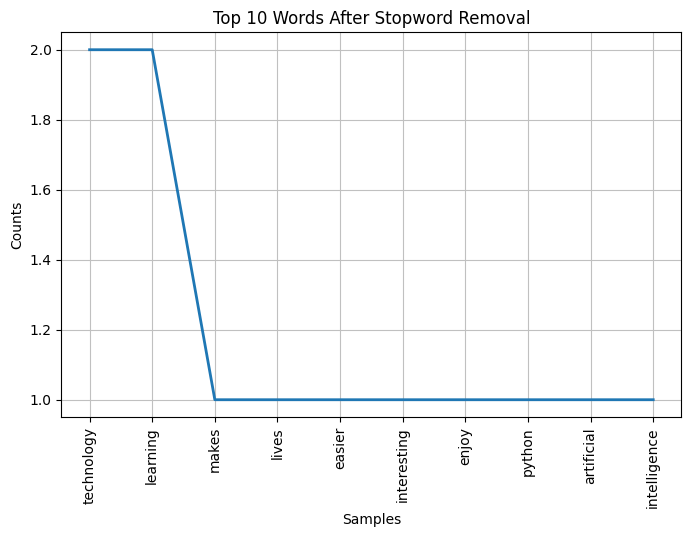

In [3]:

import re
import nltk
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist


nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

text = """Technology makes our lives easier and more interesting.
I enjoy learning Python, artificial intelligence, and machine learning.
These technologies help us solve problems and create useful applications.
I also like exploring new software tools and building small projects.
In the future, I want to develop innovative solutions using technology."""

print("Original Text:\n", text)

clean_text = re.sub(r'[^\w\s]', '', text.lower())
print("\nCleaned Text:\n", clean_text)

words = word_tokenize(text)
sentences = sent_tokenize(text)

print("\nWord Tokens:\n", words)
print("\nSentence Tokens:\n", sentences)

split_words = clean_text.split()
nltk_words = word_tokenize(clean_text)

print("\nTokens using split():\n", split_words)
print("\nTokens using word_tokenize():\n", nltk_words)

print("\nAre both token lists identical?", split_words == nltk_words)


stop_words = set(stopwords.words('english'))
filtered_words = [word for word in nltk_words if word not in stop_words]

print("\nTokens after removing stopwords:\n", filtered_words)


freq_dist = FreqDist(filtered_words)

print("\nWord Frequency Distribution:")
for word, count in freq_dist.most_common():
    print(word, ":", count)


plt.figure(figsize=(8, 5))
freq_dist.plot(10, title="Top 10 Words After Stopword Removal")
plt.show()



**Q2**

In [5]:

from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.corpus import stopwords
import re
import nltk

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
words = re.findall(r'\b[A-Za-z]+\b', text.lower())

stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words if word not in stop_words]

porter = PorterStemmer()
stemmed_words = [porter.stem(word) for word in filtered_words]

lemmatizer = WordNetLemmatizer()
lemmatized_words = [lemmatizer.lemmatize(word) for word in filtered_words]

print("After Removing Stopwords:")
print(filtered_words)

print("\nStemmed Words:")
print(stemmed_words)

print("\nLemmatized Words:")
print(lemmatized_words)

print("\nComparison:")
for word, stem, lemma in zip(filtered_words, stemmed_words, lemmatized_words):
    print(word, "-> Stem:", stem, "| Lemma:", lemma)



[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


After Removing Stopwords:
['technology', 'makes', 'lives', 'easier', 'interesting', 'enjoy', 'learning', 'python', 'artificial', 'intelligence', 'machine', 'learning', 'technologies', 'help', 'us', 'solve', 'problems', 'create', 'useful', 'applications', 'also', 'like', 'exploring', 'new', 'software', 'tools', 'building', 'small', 'projects', 'future', 'want', 'develop', 'innovative', 'solutions', 'using', 'technology']

Stemmed Words:
['technolog', 'make', 'live', 'easier', 'interest', 'enjoy', 'learn', 'python', 'artifici', 'intellig', 'machin', 'learn', 'technolog', 'help', 'us', 'solv', 'problem', 'creat', 'use', 'applic', 'also', 'like', 'explor', 'new', 'softwar', 'tool', 'build', 'small', 'project', 'futur', 'want', 'develop', 'innov', 'solut', 'use', 'technolog']

Lemmatized Words:
['technology', 'make', 'life', 'easier', 'interesting', 'enjoy', 'learning', 'python', 'artificial', 'intelligence', 'machine', 'learning', 'technology', 'help', 'u', 'solve', 'problem', 'create', 'u

**Q3**

In [6]:

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import pandas as pd
import numpy as np

texts = [
    "Artificial intelligence is changing the world",
    "Machine learning helps computers learn from data",
    "Artificial intelligence and machine learning are useful technologies"
]

cv = CountVectorizer()
bow = cv.fit_transform(texts)

bow_df = pd.DataFrame(
    bow.toarray(),
    columns=cv.get_feature_names_out(),
    index=["Text 1", "Text 2", "Text 3"]
)

print("Bag of Words Representation:")
display(bow_df)

tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform(texts)

tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf.get_feature_names_out(),
    index=["Text 1", "Text 2", "Text 3"]
)

print("\nTF-IDF Scores:")
display(tfidf_df.round(3))

terms = tfidf.get_feature_names_out()

for i, text in enumerate(texts):
    scores = tfidf_matrix[i].toarray().flatten()
    top_indices = np.argsort(scores)[-3:][::-1]

    print(f"\nText {i + 1}: {text}")
    print("Top 3 keywords:")

    for idx in top_indices:
        print(f"{terms[idx]}: {scores[idx]:.3f}")



Bag of Words Representation:


,and,are,artificial,changing,computers,data,from,helps,intelligence,is,learn,learning,machine,technologies,the,useful,world
Text 1,0,0,1,1,0,0,0,0,1,1,0,0,0,0,1,0,1
Text 2,0,0,0,0,1,1,1,1,0,0,1,1,1,0,0,0,0
Text 3,1,1,1,0,0,0,0,0,1,0,0,1,1,1,0,1,0



TF-IDF Scores:


,and,are,artificial,changing,computers,data,from,helps,intelligence,is,learn,learning,machine,technologies,the,useful,world
Text 1,0.000,0.000,0.335,0.44,0.000,0.000,0.000,0.000,0.335,0.44,0.000,0.000,0.000,0.000,0.44,0.000,0.44
Text 2,0.000,0.000,0.000,0.00,0.403,0.403,0.403,0.403,0.000,0.00,0.403,0.307,0.307,0.000,0.00,0.000,0.00
Text 3,0.398,0.398,0.303,0.00,0.000,0.000,0.000,0.000,0.303,0.00,0.000,0.303,0.303,0.398,0.00,0.398,0.00



Text 1: Artificial intelligence is changing the world
Top 3 keywords:
world: 0.440
the: 0.440
is: 0.440

Text 2: Machine learning helps computers learn from data
Top 3 keywords:
learn: 0.403
computers: 0.403
data: 0.403

Text 3: Artificial intelligence and machine learning are useful technologies
Top 3 keywords:
useful: 0.398
and: 0.398
technologies: 0.398


**Q4**

In [7]:

import re
import nltk
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

text1 = """Artificial intelligence helps computers learn from data.
It is used in healthcare, education, and business.
AI can automate tasks and make predictions.
Machine learning is an important part of AI.
It helps solve complex problems efficiently."""

text2 = """Blockchain is a technology that stores data securely.
It uses distributed networks to record transactions.
Blockchain is popular in cryptocurrency and finance.
It provides transparency and prevents data tampering.
Many businesses use blockchain for secure transactions."""

def preprocess(text):
    text = text.lower()
    text = re.sub(r'[^\w\s]', '', text)
    tokens = nltk.word_tokenize(text)
    return tokens

tokens1 = preprocess(text1)
tokens2 = preprocess(text2)

print("Text 1 Tokens:", tokens1)
print("Text 2 Tokens:", tokens2)

set1 = set(tokens1)
set2 = set(tokens2)

jaccard = len(set1 & set2) / len(set1 | set2)

print("\nJaccard Similarity:", round(jaccard, 4))

texts = [text1, text2]

vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform(texts)

cosine = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:2])[0][0]

print("Cosine Similarity:", round(cosine, 4))

print("\nAnalysis:")
if cosine > jaccard:
    print("Cosine similarity gives a higher similarity score because it considers TF-IDF word weights.")
elif jaccard > cosine:
    print("Jaccard similarity gives a higher score based on the proportion of shared unique words.")
else:
    print("Both metrics give the same similarity score.")



Text 1 Tokens: ['artificial', 'intelligence', 'helps', 'computers', 'learn', 'from', 'data', 'it', 'is', 'used', 'in', 'healthcare', 'education', 'and', 'business', 'ai', 'can', 'automate', 'tasks', 'and', 'make', 'predictions', 'machine', 'learning', 'is', 'an', 'important', 'part', 'of', 'ai', 'it', 'helps', 'solve', 'complex', 'problems', 'efficiently']
Text 2 Tokens: ['blockchain', 'is', 'a', 'technology', 'that', 'stores', 'data', 'securely', 'it', 'uses', 'distributed', 'networks', 'to', 'record', 'transactions', 'blockchain', 'is', 'popular', 'in', 'cryptocurrency', 'and', 'finance', 'it', 'provides', 'transparency', 'and', 'prevents', 'data', 'tampering', 'many', 'businesses', 'use', 'blockchain', 'for', 'secure', 'transactions']

Jaccard Similarity: 0.0909
Cosine Similarity: 0.1861

Analysis:
Cosine similarity gives a higher similarity score because it considers TF-IDF word weights.


**Jaccard Similarity:** It measures the overlap of unique words between two texts without considering their frequency. The score is low because the texts share very few words, such as "data".

**Cosine Similarity:** It compares the TF-IDF vectors of both texts and considers the importance of words. Its score is also low because the texts discuss different technologies.

**Conclusion:** Cosine similarity with TF-IDF provides better insight in this case because it considers word importance. Jaccard similarity is useful for checking vocabulary overlap, while cosine similarity is more suitable for comparing text similarity using weighted features.


**Q5**

Review: This product is amazing and the quality is excellent.
Polarity: 0.8
Subjectivity: 0.95
Sentiment: Positive

Review: I am very happy with this purchase. It works perfectly.
Polarity: 1.0
Subjectivity: 1.0
Sentiment: Positive

Review: The product is terrible and the quality is very poor.
Polarity: -0.76
Subjectivity: 0.89
Sentiment: Negative

Review: I am disappointed because it stopped working quickly.
Polarity: -0.208
Subjectivity: 0.625
Sentiment: Negative

Review: The product is okay and works as expected.
Polarity: 0.2
Subjectivity: 0.45
Sentiment: Positive



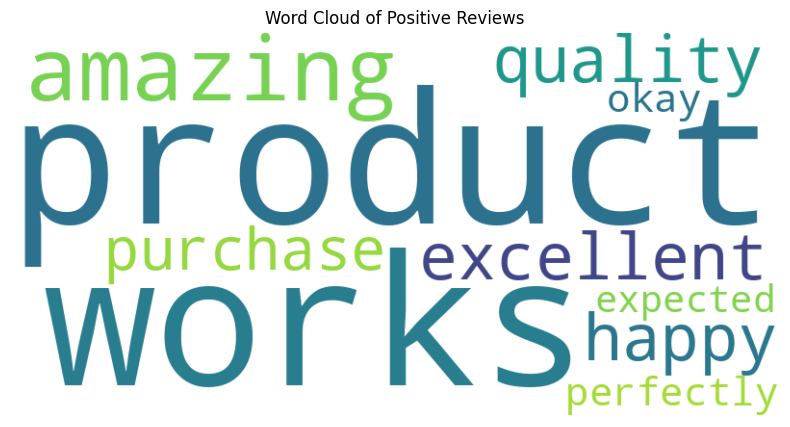

In [9]:
from textblob import TextBlob
import matplotlib.pyplot as plt
from wordcloud import WordCloud

reviews = [
    "This product is amazing and the quality is excellent.",
    "I am very happy with this purchase. It works perfectly.",
    "The product is terrible and the quality is very poor.",
    "I am disappointed because it stopped working quickly.",
    "The product is okay and works as expected."
]

positive_reviews = []

for review in reviews:
    blob = TextBlob(review)
    polarity = blob.sentiment.polarity
    subjectivity = blob.sentiment.subjectivity

    if polarity > 0.1:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < -0.1:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print("Review:", review)
    print("Polarity:", round(polarity, 3))
    print("Subjectivity:", round(subjectivity, 3))
    print("Sentiment:", sentiment)
    print()

if positive_reviews:
    text = " ".join(positive_reviews)

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white"
    ).generate(text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud of Positive Reviews")
    plt.show()


**Q6**

In [14]:

import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.utils import to_categorical

text = """
Technology is changing the world rapidly.
Artificial intelligence helps people solve complex problems.
Machine learning allows computers to learn from data.
Python is a popular programming language.
Students use technology to develop innovative applications.
Computer science provides many career opportunities.
Learning new skills helps students build their future.
Modern technology improves communication and education.
"""

tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1
sequences = []

for line in text.strip().split('\n'):
    tokens = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(tokens)):
        sequences.append(tokens[:i + 1])

max_len = max(len(seq) for seq in sequences)

sequences = np.array([
    np.pad(seq, (max_len - len(seq), 0))
    for seq in sequences
])

X = sequences[:, :-1]
y = to_categorical(sequences[:, -1], num_classes=total_words)

model = Sequential([
    Embedding(total_words, 32, input_length=max_len - 1),
    LSTM(64),
    Dense(total_words, activation='softmax')
])

model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.fit(X, y, epochs=200, verbose=0)


def generate_text(seed, next_words=8):
    for _ in range(next_words):
        tokens = tokenizer.texts_to_sequences([seed])[0]
        tokens = tokens[-(max_len - 1):]

        padded = np.pad(
            tokens,
            (max(0, max_len - 1 - len(tokens)), 0)
        )

        prediction = model.predict(
            np.array([padded]), verbose=0
        )

        next_index = np.argmax(prediction)
        next_word = tokenizer.index_word.get(next_index, '')

        if not next_word:
            break

        seed += ' ' + next_word

    return seed


print(generate_text("technology", 8))
print(generate_text("machine learning", 8))
print(generate_text("students", 8))




technology is changing the world rapidly rapidly rapidly rapidly
machine learning allows computers to learn from data data data
students technology technology to develop innovative applications applications applications
